# Forward and Backward Propagation by hand

**Contents**
1. One neuron
2. A hidden neuron
3. A hidden layer with two neurons
4. Challenge: a dataset of 100 examples

Hidden neurons use ReLU and the output neuron uses a sigmoid. $L$ is the loss on one example, $J$ the cost averaged over a dataset, and $\alpha$ the learning rate.

Cells marked **Example** can simply be run. Cells marked **Exercise** contain `# TODO` gaps for you to complete.

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def numerical_gradients(loss_fn, *params, h=1e-5):
    """Estimate the gradient of loss with respect to each parameter numerically.
    Used only as a check."""
    grads = []
    for k in range(len(params)):
        grad = np.zeros_like(np.array(params[k], dtype=float))
        for i in np.ndindex(grad.shape):
            plus = [np.array(q, dtype=float) for q in params]
            minus = [np.array(q, dtype=float) for q in params]
            plus[k][i] += h
            minus[k][i] -= h
            grad[i] = (loss_fn(*plus) - loss_fn(*minus)) / (2 * h)
        grads.append(grad)
    return grads


def gradients_match(analytic, numeric):
    """Return True if every gradient you computed matches its numerical estimate."""
    return all(np.allclose(a, n, atol=1e-6) for a, n in zip(analytic, numeric))

---
## 1. One Neuron

### Example 1: Forward pass through the output neuron

$$z = wx + b, \qquad a = \sigma(z) = \frac{1}{1 + e^{-z}}, \qquad L = -\big[y\log a + (1-y)\log(1-a)\big]$$

In [3]:
def sigmoid(z):
    """Output activation: maps any real number to (0, 1)."""
    return 1 / (1 + np.exp(-z))


def bce(a, y):
    """Binary cross-entropy loss L for one example."""
    a = np.clip(a, 1e-12, 1 - 1e-12)
    return -(y * np.log(a) + (1 - y) * np.log(1 - a))


def forward_1(x, w, b):
    """Forward pass for one sigmoid neuron. Returns z and a."""
    z = w * x + b
    a = sigmoid(z)
    return z, a

In [4]:
x, y = 2.0, 1.0 # single data point
w_init, b_init = 0.3, -0.5 # initialise w and b

z, a = forward_1(x, w_init, b_init)
print(f"z = {z:.4f}, a = {a:.4f}, L = {bce(a, y):.4f}")

z = 0.1000, a = 0.5250, L = 0.6444


### Exercise 1: Backward pass and gradient descent

Complete `backward_1` using

$$\frac{\partial L}{\partial z} = a - y, \qquad \frac{\partial L}{\partial w} = \frac{\partial L}{\partial z}\,x, \qquad \frac{\partial L}{\partial b} = \frac{\partial L}{\partial z}$$

then run 20 steps of gradient descent with $\alpha = 0.5$:

$$w \leftarrow w - \alpha\,\frac{\partial L}{\partial w} \qquad b \leftarrow b - \alpha\,\frac{\partial L}{\partial b}$$

In [12]:
def backward_1(x, y, a):
    """Backward pass for one sigmoid neuron. Returns dL/dw and dL/db."""
    # TODO: compute dL/dz, then dL/dw and dL/db
    dl_dz = a - y
    dl_dw = dl_dz * x
    dl_db = dl_dz * 1
    
    return dl_dw, dl_db

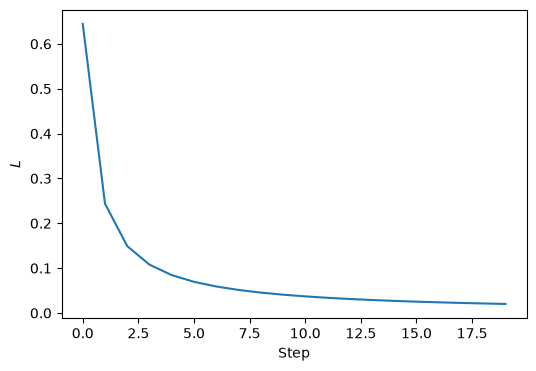

In [15]:
alpha =  0.5
history = []

w = w_init
b = b_init

for step in range(20):
    # TODO: forward pass, append the loss to history, backward pass, update w and b
    z, a = forward_1(x, w, b) 
    loss = bce(a, y)
    history.append(loss)
    dl_dw, dl_db = backward_1(x, y, a)
    w = w - alpha * dl_dw
    b = b - alpha * dl_db

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(history)
ax.set_xlabel("Step")
ax.set_ylabel("$L$")
plt.show()

In [14]:
# Check your answer (should print True True)
loss_1 = lambda w, b: bce(forward_1(x, w, b)[1], y)
z, a = forward_1(x, 0.3, -0.5)
print(gradients_match(backward_1(x, y, a), numerical_gradients(loss_1, 0.3, -0.5)), history[-1] < history[0])

True True


---
## 2. A Hidden Neuron

### Example 2: The ReLU activation

$$\text{ReLU}(z) = \max(0, z), \qquad \text{ReLU}'(z) = \begin{cases} 1 & z > 0 \\ 0 & z \le 0 \end{cases}$$

In [16]:
def relu(z):
    """Hidden activation: max(0, z)."""
    return np.maximum(0, z)


def relu_slope(z):
    """Derivative of ReLU: 1 where z > 0, otherwise 0."""
    return np.where(z > 0, 1.0, 0.0)

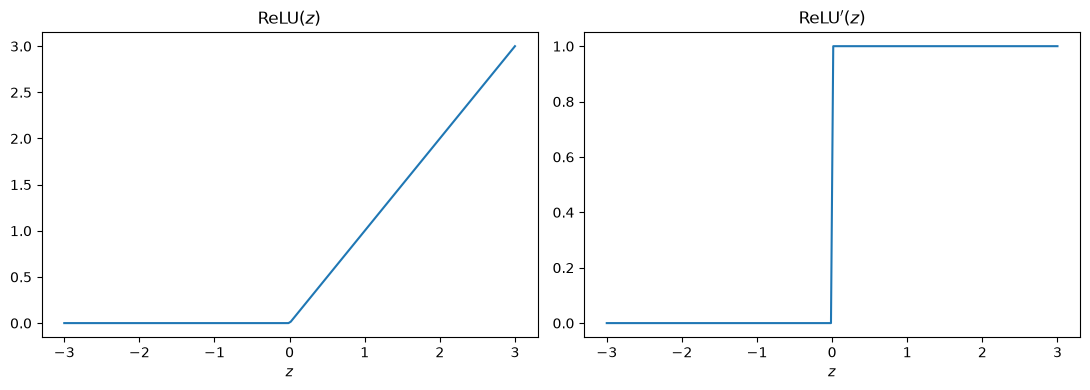

In [17]:
z = np.linspace(-3, 3, 200)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(z, relu(z))
axes[0].set_title("ReLU$(z)$")
axes[1].plot(z, relu_slope(z))
axes[1].set_title("ReLU$'(z)$")
for ax in axes:
    ax.set_xlabel("$z$")
plt.tight_layout()
plt.show()

### Exercise 2: Forward pass through a hidden neuron and the output neuron

$$z^{(1)} = w^{(1)}x + b^{(1)}, \quad a^{(1)} = \text{ReLU}(z^{(1)}), \quad z^{(2)} = w^{(2)}a^{(1)} + b^{(2)}, \quad a^{(2)} = \sigma(z^{(2)})$$

Return every intermediate value: the backward pass will need them.

In [18]:
def forward_2(x, w1, b1, w2, b2):
    """Forward pass: ReLU hidden neuron, then sigmoid output neuron. Returns z1, a1, z2, a2."""
    # TODO: compute each value in turn
    
    z1 = w1 * x + b1
    a1 = relu(z1)
    z2 = w2 * a1 + b2
    a2 = sigmoid(z2)
    return z1, a1, z2, a2

In [19]:
x, y = 1.0, 1.0
w1_init, b1_init, w2_init, b2_init = 0.5, 0.0, 1.0, 0.0

z1, a1, z2, a2 = forward_2(x, w1_init, b1_init, w2_init, b2_init)
print(f"z1 = {z1}, a1 = {a1}, z2 = {z2}, a2 = {a2}")

# Check your answer (should print True)
print(np.isclose(a2, 0.6225, atol=1e-4))

z1 = 0.5, a1 = 0.5, z2 = 0.5, a2 = 0.6224593312018546
True


### Example 3: Ingredients for the backward pass

Each step of the forward pass has a simple local derivative:

| Local derivative | Value |
|:--|:--|
| $\partial L/\partial z^{(2)}$ | $a^{(2)} - y$ |
| $\partial z^{(2)}/\partial w^{(2)}$, $\ \partial z^{(2)}/\partial b^{(2)}$ | $a^{(1)}$, $\ 1$ |
| $\partial z^{(2)}/\partial a^{(1)}$ | $w^{(2)}$ |
| $\partial a^{(1)}/\partial z^{(1)}$ | $\text{ReLU}'(z^{(1)})$ |
| $\partial z^{(1)}/\partial w^{(1)}$, $\ \partial z^{(1)}/\partial b^{(1)}$ | $x$, $\ 1$ |

The chain rule multiplies them along the path from $L$ back to each parameter, for example

$$\frac{\partial L}{\partial w^{(1)}} = \frac{\partial L}{\partial z^{(2)}}\cdot\frac{\partial z^{(2)}}{\partial a^{(1)}}\cdot\frac{\partial a^{(1)}}{\partial z^{(1)}}\cdot\frac{\partial z^{(1)}}{\partial w^{(1)}}$$

Backpropagation works from $L$ backwards and reuses each product: $\partial L/\partial z^{(2)}$ is shared by every parameter, and $\partial L/\partial z^{(1)}$ by both hidden-neuron parameters.

In [21]:
# The ingredients
dL_dz2 = a2 - y
dz2_dw2 = a1
dz2_db2 = 1.0
dz2_da1 = w2_init
da1_dz1 = relu_slope(z1)
dz1_dw1 = x
dz1_db1 = 1.0

print(f"dL/dz2 = {dL_dz2:.4f}")
print(f"dz2/dw2 = {dz2_dw2:.4f},  dz2/db2 = {dz2_db2}")
print(f"dz2/da1 = {dz2_da1:.4f}")
print(f"da1/dz1 = {da1_dz1}")
print(f"dz1/dw1 = {dz1_dw1},  dz1/db1 = {dz1_db1}")

dL/dz2 = -0.3775
dz2/dw2 = 0.5000,  dz2/db2 = 1.0
dz2/da1 = 1.0000
da1/dz1 = 1.0
dz1/dw1 = 1.0,  dz1/db1 = 1.0


### Exercise 3a: Backward pass through both neurons

Complete `backward_2` by combining the ingredients. Compute $\partial L/\partial z^{(2)}$ and $\partial L/\partial z^{(1)}$ once each, then reuse them.

In [22]:
def backward_2(x, y, w2, z1, a1, a2):
    """Backward pass for 2 neurons.
    Returns dL/dw1, dL/db1, dL/dw2, dL/db2.
    """

    # STEP 1: Output neuron
    dl_dz2 = a2 - y

    dl_dw2 = dl_dz2 * a1
    dl_db2 = dl_dz2 * 1

    # STEP 2: Backpropagate to hidden neuron
    dl_dz1 = dl_dz2 * w2 * relu_slope(z1)

    # STEP 3: Hidden neuron's gradients
    dl_dw1 = dl_dz1 * x
    dl_db1 = dl_dz1 * 1

    # STEP 4: Return all four gradients
    return dl_dw1, dl_db1, dl_dw2, dl_db2

In [23]:
# Check your answer (should print True)
loss_2 = lambda w1_init, b1_init, w2_init, b2_init: bce(forward_2(x, w1_init, b1_init, w2_init, b2_init)[3], y)
z1, a1, z2, a2 = forward_2(x, w1_init, b1_init, w2_init, b2_init)
print(gradients_match(backward_2(x, y, w2_init, z1, a1, a2), numerical_gradients(loss_2, w1_init, b1_init, w2_init, b2_init)))

True


### Exercise 3b: Watching the loss

1. Train for 50 steps with each learning rate below and plot the loss curves. Which $\alpha$ works best?
2. Repeat with $w^{(1)} = -0.5$ instead of $0.5$. The loss still falls, but print the gradients at the end: which parameters are learning, and why?


Learning rate: 0.1
dL/dw1 = -0.000000
dL/db1 = -0.000000
dL/dw2 = -0.000000
dL/db2 = -0.180552

Learning rate: 1.0
dL/dw1 = -0.000000
dL/db1 = -0.000000
dL/dw2 = -0.000000
dL/db2 = -0.020091

Learning rate: 5.0
dL/dw1 = -0.000000
dL/db1 = -0.000000
dL/dw2 = -0.000000
dL/db2 = -0.003803


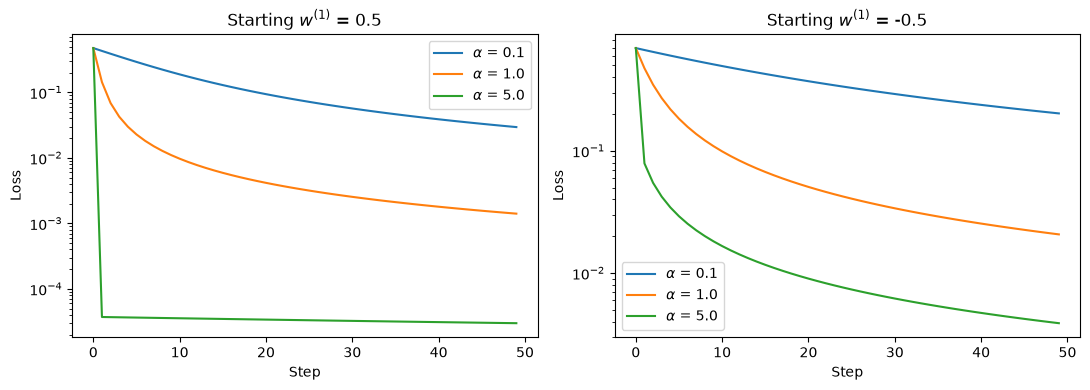

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, w1_start in zip(axes, [0.5, -0.5]):

    for alpha in [0.1, 1.0, 5.0]:

        w1, b1, w2, b2 = w1_start, 0.0, 1.0, 0.0
        history = []

        for step in range(50):

            # 1. Forward propagation
            z1, a1, z2, a2 = forward_2(x, w1, b1, w2, b2)

            # 2. Calculate loss
            loss = bce(a2, y)
            history.append(loss)

            # 3. Backpropagation
            dl_dw1, dl_db1, dl_dw2, dl_db2 = backward_2(
                x, y, w2, z1, a1, a2
            )

            # 4. Gradient descent
            w1 = w1 - alpha * dl_dw1
            b1 = b1 - alpha * dl_db1
            w2 = w2 - alpha * dl_dw2
            b2 = b2 - alpha * dl_db2

        # 5. Plot loss
        ax.plot(history, label=f"$\\alpha$ = {alpha}")

        # 6. Print gradients for negative starting weight
        if w1_start == -0.5:

            # Recalculate gradients using final parameters
            z1, a1, z2, a2 = forward_2(x, w1, b1, w2, b2)

            dl_dw1, dl_db1, dl_dw2, dl_db2 = backward_2(
                x, y, w2, z1, a1, a2
            )

            print(f"\nLearning rate: {alpha}")
            print(f"dL/dw1 = {dl_dw1:.6f}")
            print(f"dL/db1 = {dl_db1:.6f}")
            print(f"dL/dw2 = {dl_dw2:.6f}")
            print(f"dL/db2 = {dl_db2:.6f}")

    ax.set_title(f"Starting $w^{{(1)}}$ = {w1_start}")
    ax.set_xlabel("Step")
    ax.set_ylabel("Loss")
    ax.set_yscale("log")
    ax.legend()

plt.tight_layout()
plt.show()

---
## 3. A Hidden Layer with Two Neurons

Now `w1`, `b1` and `w2` are NumPy arrays of length 2, one entry per hidden neuron, and

$$z^{(2)} = w^{(2)}_1 a^{(1)}_1 + w^{(2)}_2 a^{(1)}_2 + b^{(2)} = w^{(2)} \cdot a^{(1)} + b^{(2)}$$

NumPy applies `*`, `+`, `relu` and `relu_slope` to each entry separately, and `w2 @ a1` is the dot product.

### Exercise 4: Forward pass through the network

In [26]:
def forward_3(x, w1, b1, w2, b2):
    """Forward pass: input -> 2 ReLU hidden neurons -> sigmoid output. Returns z1, a1, z2, a2."""
    # TODO: z1 and a1 are arrays of length 2; z2 and a2 are numbers. Think multiply or dot product?
    z1 = np.array([w1[0] * x + b1[0], w1[1] * x + b1[1]])
    a1 = relu(z1)
    z2 = np.dot(w2, a1) + b2
    a2 = sigmoid(z2)

    return z1, a1, z2, a2

In [27]:
x, y = 0.5, 1.0
w1_init = np.array([1.0, -1.0])
b1_init = np.array([0.5, 0.2])
w2_init = np.array([1.5, -0.5])
b2_init = 0.1

z1, a1, z2, a2 = forward_3(x, w1_init, b1_init, w2_init, b2_init)
print(f"z1 = {z1}, a1 = {a1}, z2 = {z2}, a2 = {a2}")

# Check your answer (should print True)
print(np.isclose(a2, 0.8320, atol=1e-4))

z1 = [ 1.  -0.3], a1 = [1. 0.], z2 = 1.6, a2 = 0.8320183851339245
True


### Exercise 5: Backward pass through the network

Both hidden neurons share $\partial L/\partial z^{(2)}$, then each goes back through its own $w^{(2)}_j$ and its own ReLU.

In [ ]:
def backward_3(x, y, w2, z1, a1, a2):
    """Backward pass for forward_3. Returns dL/dw1, dL/db1, dL/dw2, dL/db2 (same shapes as the parameters)."""
    # TODO: output neuron

    # TODO: hidden layer (arrays of length 2)

    return

In [ ]:
dLdw1, dLdb1, dLdw2, dLdb2 = backward_3(x, y, w2_init, z1, a1, a2)
print(f"dL/dw1 = {dLdw1}, dL/db1 = {dLdb1}, dL/dw2 = {dLdw2}, dL/db2 = {dLdb2}")

# Check your answer (should print True)
loss_3 = lambda w1_init, b1_init, w2_init, b2_init: bce(forward_3(x, w1_init, b1_init, w2_init, b2_init)[3], y)
print(gradients_match((dLdw1, dLdb1, dLdw2, dLdb2), numerical_gradients(loss_3, w1_init, b1_init, w2_init, b2_init)))

### Exercise 6: The gradient is the slope of the loss

Plot $L$ as you vary $w^{(2)}_1$ (`w2[0]`) alone, keeping every other parameter fixed.
Then draw the tangent line at the current value, using the slope from `backward_3`. Does it touch the curve? Which way will gradient descent move $w^{(2)}_1$?

Why are the gradients for hidden neuron 2 exactly zero?

In [ ]:
w_values = np.linspace(-2, 4, 200)
losses = []

for w in w_values:
    w2_try = w2_init.copy()
    # TODO: set w2_try[0] to w which corresponds to the first weight of the second layer, then append the loss to losses

    losses.append(loss_3(w1_init, b1_init, w2_try, b2_init))

# TODO: the slope dL/dw2_1 at the current parameters, from backward_3


w_now = w2_try[0]
L_now = loss_3(w1_init, b1_init, w_now, b2_init)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(w_values, losses, label="$L$")
# TODO: plot the tangent line L_now + slope * (w - w_now) for w between w_now - 1 and w_now + 1

ax.scatter([w_now], [L_now], color="red", zorder=3)
ax.set_xlabel("$w^{(2)}_1$")
ax.set_ylabel("$L$")
ax.legend()
plt.show()